In [12]:
import sys, neo4j, pandas
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from neo4j import GraphDatabase
print(sys.version)
print(neo4j.__version__)

3.10.22 (main, Oct  9 2026, 15:18:58) [MSC v.1944 64 bit (AMD64)]
6.4.1


#SETUP KODE

In [ ]:

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "PASSWORD")   # ganti sementara dengan password asli
DB = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run(q, **params):
    with driver.session(database=DB) as s:
        return s.run(q, **params).data()

print("Terhubung")

Terhubung


### 2.1 Wrangling dan EDA 

In [ ]:
#1.Menentukan periode waktu
P1_START, P1_END = "2015-05-12", "2015-06-26"   
P2_START, P2_END = "2015-07-06", "2015-08-10"   

Deskripsi
- P1 (training): 2015-05-12 s.d. sebelum 2015-06-26
- P2 (testing): 2015-07-06 s.d. sebelum 2015-08-10

In [8]:
#2. Filter timestamp
df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")   # UTC

def ambil_periode(df, start, end):
    return df[(df["datetime"] >= start) & (df["datetime"] < end)].copy()

p1 = ambil_periode(df, P1_START, P1_END)
p2 = ambil_periode(df, P2_START, P2_END)

p1.drop(columns="datetime").to_csv("data/events_p1.csv", index=False)
p2.drop(columns="datetime").to_csv("data/events_p2.csv", index=False)

print("P1:", p1.shape, "| P2:", p2.shape)
print("Visitor di P1 dan P2:", len(set(p1.visitorid) & set(p2.visitorid)))

P1: (940430, 6) | P2: (762421, 6)
Visitor di P1 dan P2: 16174


In [9]:
#3.Subgraph
df_nodes = pd.DataFrame(run("""MATCH (n) RETURN labels(n)[0] AS jenis_simpul, 
                            count(*) AS jumlah ORDER BY jumlah DESC"""))
print(df_nodes)
df_rels = pd.DataFrame(run("""MATCH (a)-[r]->(b)
                            RETURN labels(a)[0] AS dari, type(r) AS relasi, 
                            labels(b)[0] AS ke, count(*) AS jumlah
                            ORDER BY jumlah DESC
                            """))
print(df_rels)
print("Total relasi:", df_rels["jumlah"].sum())

  jenis_simpul  jumlah
0      Visitor  479153
1         Item  145405
      dari         relasi    ke  jumlah
0  Visitor         VIEWED  Item  909730
1  Visitor  ADDED_TO_CART  Item   23038
2  Visitor         BOUGHT  Item    7662
Total relasi: 940430


In [11]:
#4.VSM untuk simpul User (Visitor), bobot : (view=1, addtocart=3, transaction=5)
p1 = pd.read_csv("data/events_p1.csv")
bobot = {"view": 1, "addtocart": 3, "transaction": 5}
p1["w"] = p1["event"].map(bobot)
# agregasi bobot per (visitor, item)
agg = p1.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()
users = agg["visitorid"].astype("category")
items = agg["itemid"].astype("category")
X_user = csr_matrix(
    (agg["w"].values, (users.cat.codes, items.cat.codes)),
    shape=(users.cat.categories.size, items.cat.categories.size),)
print("Shape (user x item):", X_user.shape)
print("Dimensi vektor user (jumlah item):", X_user.shape[1])
print("Entri non-nol:", X_user.nnz)
print("Density:", X_user.nnz / (X_user.shape[0] * X_user.shape[1]))
nnz_per_user = np.diff(X_user.indptr)
print("Item per user -> rata-rata:", nnz_per_user.mean(), "| median:", np.median(nnz_per_user), "| maks:", nnz_per_user.max())


Shape (user x item): (479153, 145405)
Dimensi vektor user (jumlah item): 145405
Entri non-nol: 726123
Density: 1.0422133717162307e-05
Item per user -> rata-rata: 1.5154303531439852 | median: 1.0 | maks: 1201


# Analisis no. 4
Karakteristik VSM User
- Setiap Visitor dipetakan menjadi vektor berdimensi 145.405 (satu dimensi per Item).
- Shape matriks User x Item = (479.153, 145.405); bobot: view=1, addtocart=3, transaction=5.
- Matriks sangat sparse: 726.123 entri non-nol, density 1,04e-5.
- Rata-rata 1,52 item per user (median 1); maksimum 1.201 (outlier/bot).
- Dense butuh ratusan GB, maka disimpan sebagai CSR.
- Plot networkx adalah sampel 15 user teraktif dan 40 item terpopuler; graf bipartit.
- Konsekuensi: banyak user hanya punya 1 item, sehingga vektornya hampir tidak punya
  irisan dengan user lain, dan similarity antar-user kebanyakan 0.

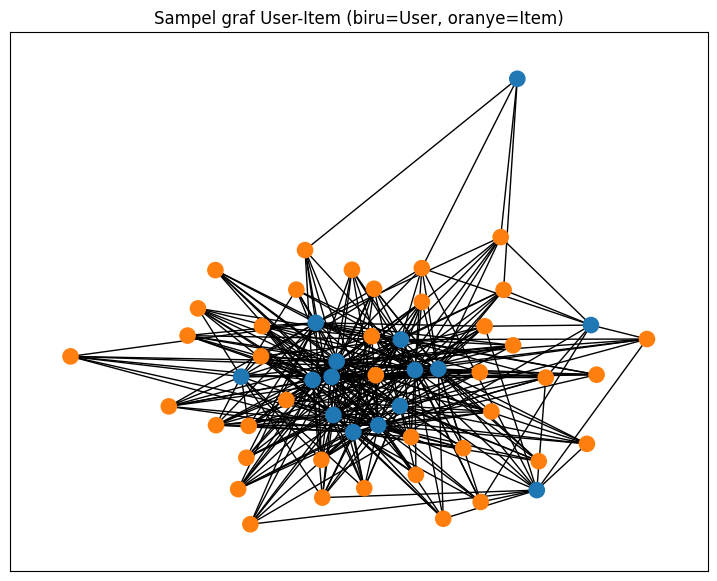

In [ ]:
#4.1 plot network
top_users = agg.groupby("visitorid").size().sort_values(ascending=False).head(15).index
sub = agg[agg["visitorid"].isin(top_users)]
# batasi item agar plot terbaca
sub = sub[sub["itemid"].isin(sub["itemid"].value_counts().head(40).index)]
G = nx.Graph()
for r in sub.itertuples():
    G.add_edge(f"U{r.visitorid}", f"I{r.itemid}", weight=r.w)
warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx(G, node_color=warna, node_size=120, font_size=6, with_labels=False)
plt.title("Sampel graf User-Item (biru=User, oranye=Item)")
plt.show()

In [14]:
#5. VSM simpul Item
#5.1 matriks item x User
X_item = X_user.T.tocsr()   # (item x user)
print("Shape (item x user):", X_item.shape)
print("Dimensi vektor item (jumlah user):", X_item.shape[1])
print("Entri non-nol:", X_item.nnz)
print("Density:", X_item.nnz / (X_item.shape[0] * X_item.shape[1]))
nnz_per_item = np.diff(X_item.indptr)
print("User per item -> rata-rata:", nnz_per_item.mean(),
      "| median:", np.median(nnz_per_item), "| maks:", nnz_per_item.max())
print("Item dengan >= 2 user:", (nnz_per_item >= 2).sum(), "dari", len(nnz_per_item))
print("User dengan >= 2 item:", (np.diff(X_user.indptr) >= 2).sum(), "dari", X_user.shape[0])

Shape (item x user): (145405, 479153)
Dimensi vektor item (jumlah user): 479153
Entri non-nol: 726123
Density: 1.0422133717162307e-05
User per item -> rata-rata: 4.9937966369794715 | median: 2.0 | maks: 1068
Item dengan >= 2 user: 80538 dari 145405
User dengan >= 2 item: 96353 dari 479153


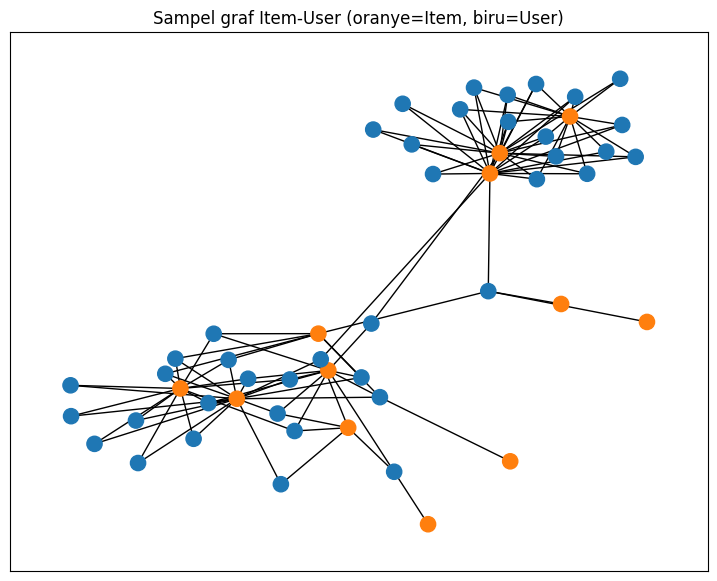

In [15]:
#5.2 plot networkx
top_items = agg.groupby("itemid").size().sort_values(ascending=False).head(15).index
sub = agg[agg["itemid"].isin(top_items)]
sub = sub[sub["visitorid"].isin(sub["visitorid"].value_counts().head(40).index)]

G = nx.Graph()
for r in sub.itertuples():
    G.add_edge(f"I{r.itemid}", f"U{r.visitorid}", weight=r.w)

warna = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G.nodes]
plt.figure(figsize=(9, 7))
nx.draw_networkx(G, node_color=warna, node_size=120, with_labels=False)
plt.title("Sampel graf Item-User (oranye=Item, biru=User)")
plt.savefig("plot_item_user.png", dpi=150)
plt.show()

# Karakteristik VSM Item
- Setiap Item dipetakan menjadi vektor berdimensi 479.153 (satu dimensi per User).
- Shape = (145.405, 479.153), transpos dari matriks User x Item; non-nol dan
  density sama persis (726.123; 1,04e-5).
- Rata-rata ... user per item (median ...; maks ...).
- Item cenderung punya lebih banyak irisan dibanding user, karena item populer
  dilihat banyak user, sedangkan kebanyakan user hanya menyentuh 1 item.
- Plot: sampel 15 item terpopuler dan 40 user teraktif; graf bipartit.